# Question 1

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.data_loader import load_question
from src.model import FlexibleConsumerModel
from src.plotting import plot_duals, plot_inputs, plot_schedule

RESULTS_DIR = Path("results")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)


In [7]:
def run_question_1_case(case_name):
    """Run one Q1 base case and display/save all required outputs."""
    data = load_question(case_name)
    results = FlexibleConsumerModel(data).build().solve()
    hourly = results.hourly.copy()

    # Effective grid prices.
    hourly["effective_import_price"] = data.energy_price + data.import_tariff
    hourly["effective_export_price"] = data.energy_price - data.export_tariff

    # Quantities used in the report.
    hourly["pv_curtailed"] = hourly["pv_available"] - hourly["pv"]
    hourly["net_grid_import"] = hourly["import"] - hourly["export"]
    hourly["balance_residual"] = (
        hourly["import"] + hourly["pv"]
        - hourly["load"] - hourly["export"]
    )

    # Separate economic components required in Q1(e).
    hourly["import_cost"] = (
        hourly["effective_import_price"] * hourly["import"]
    )
    hourly["export_revenue"] = (
        hourly["effective_export_price"] * hourly["export"]
    )
    hourly["pv_production_cost"] = data.pv_marginal_cost * hourly["pv"]
    hourly["consumption_utility"] = data.consumption_utility * hourly["load"]
    hourly["procurement_cost"] = (
        hourly["import_cost"]
        + hourly["pv_production_cost"]
        - hourly["export_revenue"]
    )
    hourly["net_surplus"] = (
        hourly["consumption_utility"] - hourly["procurement_cost"]
    )
    hourly["objective_contribution"] = -hourly["net_surplus"]

    summary = pd.Series(
        {
            "status": results.status,
            "minimized objective [DKK]": results.objective,
            "import cost [DKK]": hourly["import_cost"].sum(),
            "export revenue [DKK]": hourly["export_revenue"].sum(),
            "PV production cost [DKK]": hourly["pv_production_cost"].sum(),
            "procurement cost [DKK]": hourly["procurement_cost"].sum(),
            "consumption utility [DKK]": hourly["consumption_utility"].sum(),
            "net surplus [DKK]": hourly["net_surplus"].sum(),
            "import [kWh]": hourly["import"].sum(),
            "export [kWh]": hourly["export"].sum(),
            "load [kWh]": hourly["load"].sum(),
            "PV available [kWh]": hourly["pv_available"].sum(),
            "PV produced [kWh]": hourly["pv"].sum(),
            "PV curtailed [kWh]": hourly["pv_curtailed"].sum(),
        },
        name=case_name,
    )

    # Basic consistency checks.
    assert np.isclose(
        hourly["objective_contribution"].sum(),
        results.objective,
        atol=1e-6,
    )
    assert hourly["balance_residual"].abs().max() <= 1e-6
    assert not (
        (hourly["import"] > 1e-7) & (hourly["export"] > 1e-7)
    ).any()

    output_folder = RESULTS_DIR / case_name
    output_folder.mkdir(parents=True, exist_ok=True)

    # Use the save and plotting functions already provided by the project.
    results.save(output_folder)
    hourly.to_csv(
        output_folder / f"{case_name}_report_table.csv",
        index_label="hour",
    )
    summary.to_csv(output_folder / f"{case_name}_economic_summary.csv")

    plot_inputs(data, save_to=output_folder / "inputs.png")
    plot_schedule(results, data, save_to=output_folder / "schedule.png")
    plot_duals(results, data, save_to=output_folder / "duals.png")

    print("\n" + "=" * 80)
    print(case_name)
    print("=" * 80)
    print(data.summary())
    print("\nEconomic and energy summary")
    display(summary.to_frame("value").round(4))

    dual_columns = [
        column for column in hourly.columns if column.startswith("dual_")
    ]
    report_columns = [
        "price",
        "effective_import_price",
        "effective_export_price",
        "pv_available",
        "import",
        "export",
        "load",
        "pv",
        "pv_curtailed",
    ] + dual_columns

    print("\nHourly primal and dual results")
    display(hourly[report_columns].round(4))
    plt.show()

    return {
        "data": data,
        "results": results,
        "hourly": hourly,
        "summary": summary,
    }



Q1_caseA
Case                 : Q1_caseA
Consumer             : C_01_A
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.41 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : 1.43
Min daily energy     : None
Reference profile    : no
Disutility lin/quad  : None / None
Battery              : no
Next-day forecasts   : yes

Economic and energy summary


,value
status,OPTIMAL
minimized objective [DKK],-2.6088
import cost [DKK],16.5
export revenue [DKK],5.7
PV production cost [DKK],37.9854
procurement cost [DKK],48.7854
consumption utility [DKK],51.3942
net surplus [DKK],2.6088
import [kWh],12.0
export [kWh],3.0



Hourly primal and dual results


,price,effective_import_price,effective_export_price,pv_available,import,export,load,pv,pv_curtailed,dual_balance,dual_import_nonneg,dual_export_nonneg,dual_pv_nonneg,dual_pv_limit,dual_load_min,dual_load_max
hour,,,,,,,,,,,,,,,,
0,1.10,1.60,0.70,0.00,0.0,0.0,0.00,0.00,0.0,1.60,0.00,0.90,0.00,-0.19,0.17,0.00
1,1.05,1.55,0.65,0.00,0.0,0.0,0.00,0.00,0.0,1.55,0.00,0.90,0.00,-0.14,0.12,0.00
2,1.00,1.50,0.60,0.00,0.0,0.0,0.00,0.00,0.0,1.50,0.00,0.90,0.00,-0.09,0.07,0.00
3,0.90,1.40,0.50,0.00,6.0,0.0,6.00,0.00,0.0,1.40,0.00,0.90,0.01,0.00,0.00,-0.03
4,0.85,1.35,0.45,0.00,6.0,0.0,6.00,0.00,0.0,1.35,0.00,0.90,0.06,0.00,0.00,-0.08
5,1.01,1.51,0.61,0.30,0.0,0.0,0.30,0.30,0.0,1.43,0.08,0.82,0.00,-0.02,0.00,0.00
6,1.05,1.55,0.65,0.84,0.0,0.0,0.84,0.84,0.0,1.43,0.12,0.78,0.00,-0.02,0.00,0.00
7,1.20,1.70,0.80,1.26,0.0,0.0,1.26,1.26,0.0,1.43,0.27,0.63,0.00,-0.02,0.00,0.00
8,1.40,1.90,1.00,0.90,0.0,0.0,0.90,0.90,0.0,1.43,0.47,0.43,0.00,-0.02,0.00,0.00


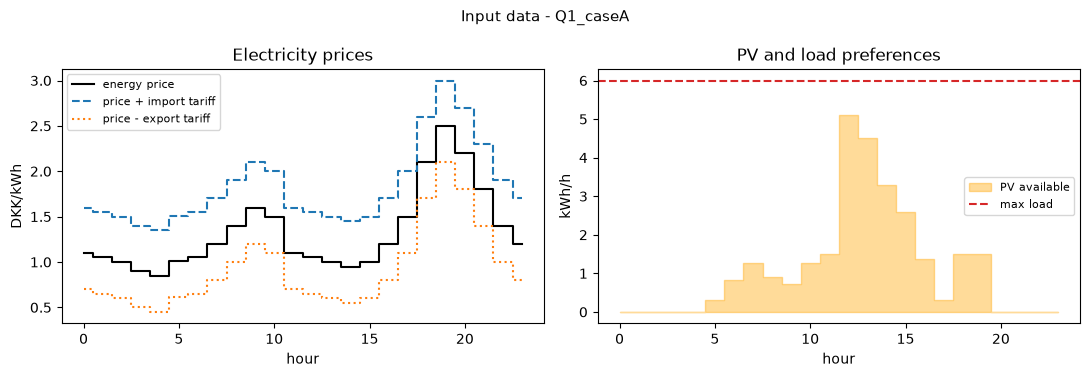

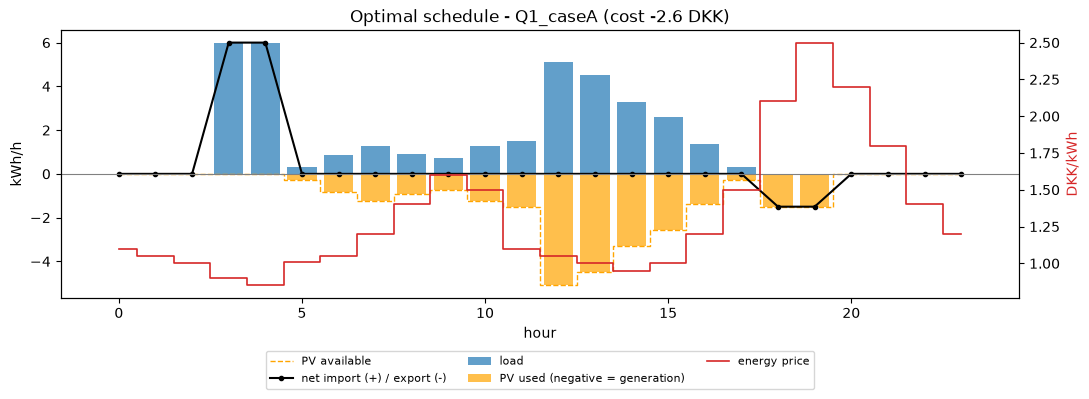

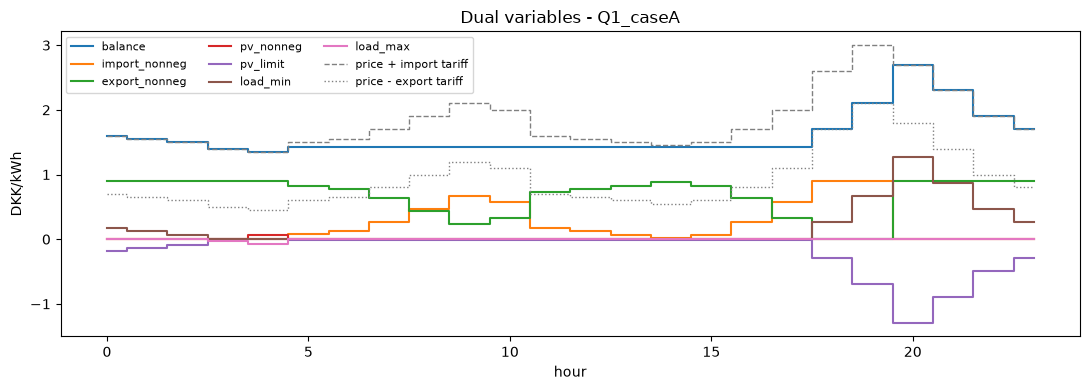


Q1_caseB
Case                 : Q1_caseB
Consumer             : C_01_B
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.47 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : 1.43
Min daily energy     : None
Reference profile    : no
Disutility lin/quad  : None / None
Battery              : no
Next-day forecasts   : yes

Economic and energy summary


,value
status,OPTIMAL
minimized objective [DKK],-1.95
import cost [DKK],16.5
export revenue [DKK],5.7
PV production cost [DKK],4.41
procurement cost [DKK],15.21
consumption utility [DKK],17.16
net surplus [DKK],1.95
import [kWh],12.0
export [kWh],3.0



Hourly primal and dual results


,price,effective_import_price,effective_export_price,pv_available,import,export,load,pv,pv_curtailed,dual_balance,dual_import_nonneg,dual_export_nonneg,dual_pv_nonneg,dual_pv_limit,dual_load_min,dual_load_max
hour,,,,,,,,,,,,,,,,
0,1.10,1.60,0.70,0.00,0.0,0.0,0.0,0.0,0.00,1.60,0.00,0.90,0.00,-0.13,0.17,0.00
1,1.05,1.55,0.65,0.00,0.0,0.0,0.0,0.0,0.00,1.55,0.00,0.90,0.00,-0.08,0.12,0.00
2,1.00,1.50,0.60,0.00,0.0,0.0,0.0,0.0,0.00,1.50,0.00,0.90,0.00,-0.03,0.07,0.00
3,0.90,1.40,0.50,0.00,6.0,0.0,6.0,0.0,0.00,1.40,0.00,0.90,0.07,0.00,0.00,-0.03
4,0.85,1.35,0.45,0.00,6.0,0.0,6.0,0.0,0.00,1.35,0.00,0.90,0.12,0.00,0.00,-0.08
5,1.01,1.51,0.61,0.30,0.0,0.0,0.0,0.0,0.30,1.43,0.08,0.82,0.04,0.00,0.00,0.00
6,1.05,1.55,0.65,0.84,0.0,0.0,0.0,0.0,0.84,1.43,0.12,0.78,0.04,0.00,0.00,0.00
7,1.20,1.70,0.80,1.26,0.0,0.0,0.0,0.0,1.26,1.43,0.27,0.63,0.04,0.00,0.00,0.00
8,1.40,1.90,1.00,0.90,0.0,0.0,0.0,0.0,0.90,1.43,0.47,0.43,0.04,0.00,0.00,0.00


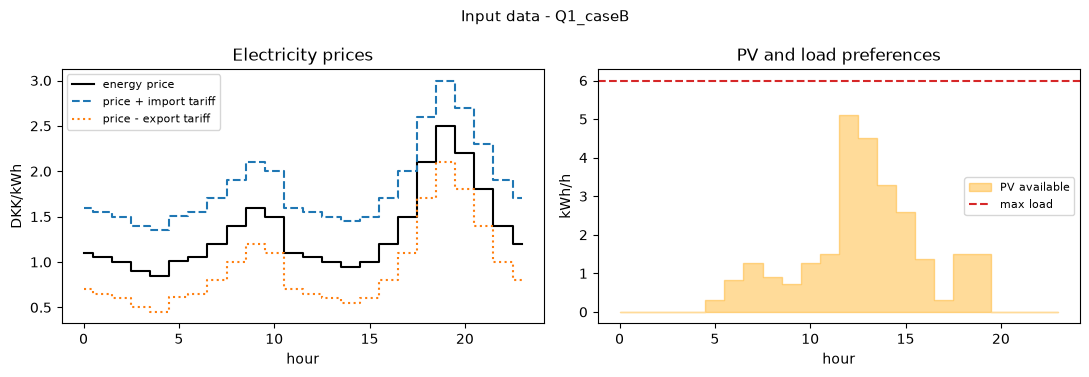

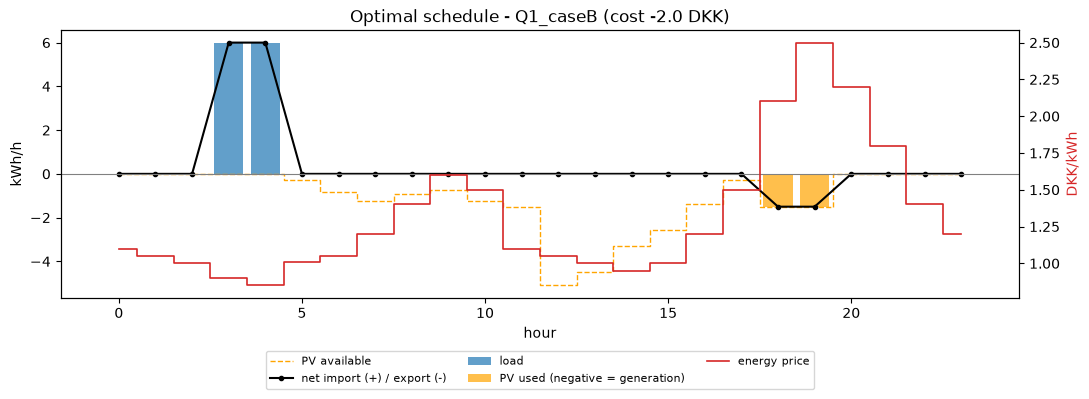

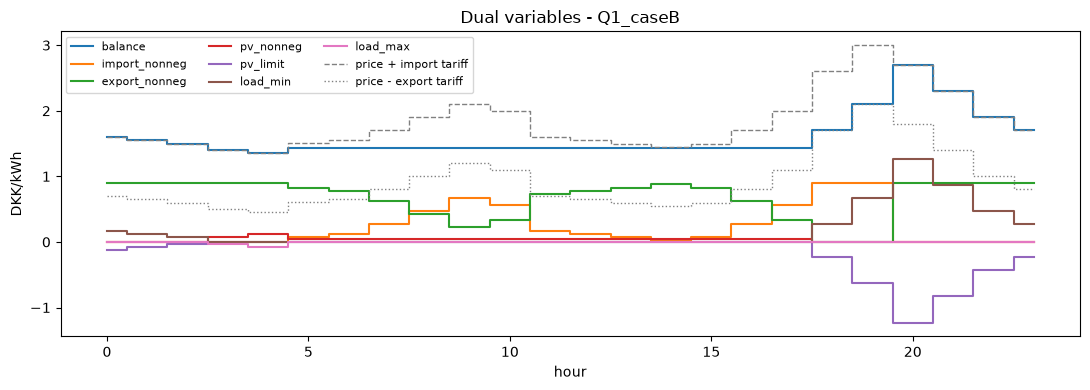

In [8]:
case_a = run_question_1_case("Q1_caseA")
case_b = run_question_1_case("Q1_caseB")


In [9]:
comparison = pd.DataFrame(
    [
        case_a["summary"].to_dict(),
        case_b["summary"].to_dict(),
    ],
    index=["Q1_caseA", "Q1_caseB"],
)
comparison.index.name = "case"

print("Case A and Case B comparison")
display(comparison.round(4))
comparison.to_csv(RESULTS_DIR / "Q1_case_comparison.csv")


Case A and Case B comparison


,status,minimized objective [DKK],import cost [DKK],export revenue [DKK],PV production cost [DKK],procurement cost [DKK],consumption utility [DKK],net surplus [DKK],import [kWh],export [kWh],load [kWh],PV available [kWh],PV produced [kWh],PV curtailed [kWh]
case,,,,,,,,,,,,,,
Q1_caseA,OPTIMAL,-2.6088,16.5,5.7,37.9854,48.7854,51.3942,2.6088,12.0,3.0,35.94,26.94,26.94,0.00
Q1_caseB,OPTIMAL,-1.9500,16.5,5.7,4.4100,15.2100,17.1600,1.9500,12.0,3.0,12.00,26.94,3.00,23.94


# Optional

Case                 : Q1_caseA
Consumer             : C_01_A
Energy price         : mean 1.32, min 0.85, max 2.50 DKK/kWh
Import/export tariff : 0.50 / 0.40 DKK/kWh
PV                   : 6.0 kW peak, 26.9 kWh available/day, marginal cost 1.41 DKK/kWh
Load bounds          : 0.0 - 6.0 kWh/h
Consumption utility  : 1.43
Min daily energy     : None
Reference profile    : no
Disutility lin/quad  : None / None
Battery              : no
Next-day forecasts   : yes
status: OPTIMAL | objective: -2.61 DKK
daily totals (kWh): import=12.0, export=3.0, load=35.9, pv=26.9


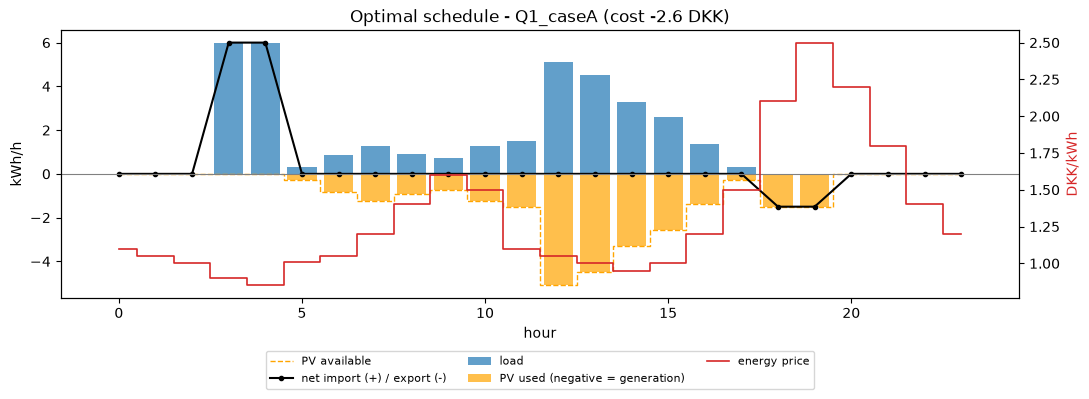

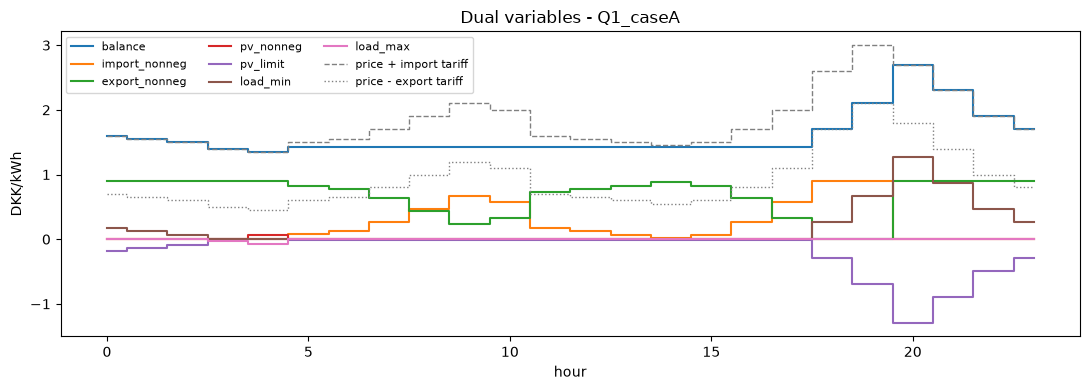

In [5]:
from src.data_loader import load_question
from src.model import FlexibleConsumerModel
from src.plotting import plot_schedule, plot_duals
from src.scenarios import scale_prices

data = load_question("Q1_caseA")
print(data.summary())

results = FlexibleConsumerModel(data).build().solve()
print(results)                    # objective, daily totals, scalar duals
results.hourly                    # DataFrame: one row per hour with variables, prices and hourly duals
plot_schedule(results, data)

plot_duals(results, data)

high_spread = scale_prices(data, factor=2.0, keep_mean=True)
results_hs = FlexibleConsumerModel(high_spread).build().solve()